# **PART D — Polynomial Regression, Overfitting and Model Complexity:**

## **Problem:**

## **D1. Linear model:**
Use Scikit-learn's LinearRegression.

Train a linear model to predict y from X.

Plot:
- The original data.
- The fitted linear regression line.
Evaluate why a straight line may not capture the entire relationship.

## **D2. Polynomial feature engineering:**
You are allowed to use:
```py
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
```

Create polynomial features of degrees:
- Degree 1.
- Degree 2.
- Degree 3.
- Degree 5.
- Degree 10.
Train a separate model for each degree.

Plot all five predictions.

Explain why a polynomial model can represent a nonlinear relationship even though the algorithm used for fitting is linear regression.

## **D3. Detect overfitting:**
Split your dataset into training and testing sets.

For every polynomial degree, calculate:
- Training MSE.
- Testing MSE.
Use:
```py
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
```

Create a comparison table.

Answer:
1. Which model underfits?
2. Which model provides the best generalization?
3. Does a high training performance guarantee good testing performance?
4. Why can increasing the polynomial degree make a model overfit?


## **Dataset:**

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

X = np.linspace(-3, 3, 60)

y = (
    2 * X**2
    + 3 * X
    + 5
    + np.random.normal(0, 3, 60)
)

X = X.reshape(-1, 1)

## **Solution:**

### D1

In [10]:
y

array([15.49014246, 12.69063657, 14.19529199, 16.00948026,  9.96746231,
        9.23841073, 13.99072664, 10.90902639,  6.59330048,  9.06577263,
        5.52557571,  5.03774323,  6.72129043, -0.14259856,  0.06569465,
        3.23815896,  1.61246901,  5.36101261,  1.50287405, -0.15992173,
        8.36534619,  3.22384892,  4.0779078 , -0.38340859,  2.314568  ,
        4.37873157,  0.73259812,  5.49365539,  2.78699516,  3.97754731,
        3.35259346, 11.06100002,  5.85149339,  3.14803929,  9.25936125,
        3.64111743,  8.48352845,  2.572584  ,  5.10306035, 10.35559376,
       12.69916877, 11.75800028, 11.69844441, 11.98493942,  9.3369132 ,
       12.53854264, 14.28312247, 19.8447364 , 18.75392295, 13.5250134 ,
       20.91881899, 19.96512087, 20.30476976, 25.42710011, 27.98297271,
       29.02308483, 25.09222965, 28.10425026, 31.48905028, 34.92663538])

In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

model = LinearRegression()

model.fit(X, y)

y_pred = model.predict(X)

print(y_pred)

[ 1.80264233  2.10558414  2.40852595  2.71146777  3.01440958  3.31735139
  3.6202932   3.92323501  4.22617683  4.52911864  4.83206045  5.13500226
  5.43794407  5.74088589  6.0438277   6.34676951  6.64971132  6.95265313
  7.25559494  7.55853676  7.86147857  8.16442038  8.46736219  8.770304
  9.07324582  9.37618763  9.67912944  9.98207125 10.28501306 10.58795488
 10.89089669 11.1938385  11.49678031 11.79972212 12.10266393 12.40560575
 12.70854756 13.01148937 13.31443118 13.61737299 13.92031481 14.22325662
 14.52619843 14.82914024 15.13208205 15.43502387 15.73796568 16.04090749
 16.3438493  16.64679111 16.94973292 17.25267474 17.55561655 17.85855836
 18.16150017 18.46444198 18.7673838  19.07032561 19.37326742 19.67620923]


In [14]:
# print weight and bais
print("Final weight:", model.coef_[0])
print("Final bias", model.intercept_)

# print mse and r2 score
print("The Mean Squared Error is:", mean_squared_error(y, y_pred))
print("R2 score is:", r2_score(y, y_pred))

Final weight: 2.9789278167227033
Final bias 10.739425781297006
The Mean Squared Error is: 47.171697246292005
R2 score is: 0.3684857459345796


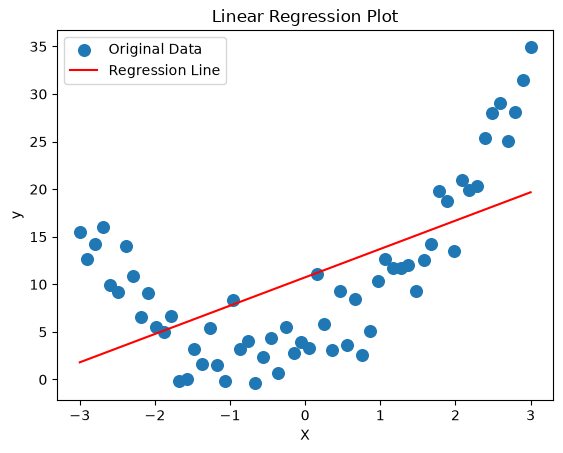

In [20]:
# now plot the data
plt.scatter(X, y, marker='o', s=70, label='Original Data')
plt.plot(X, y_pred, color='red', label='Regression Line')
plt.title("Linear Regression Plot")
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.show()

### D2

In [21]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

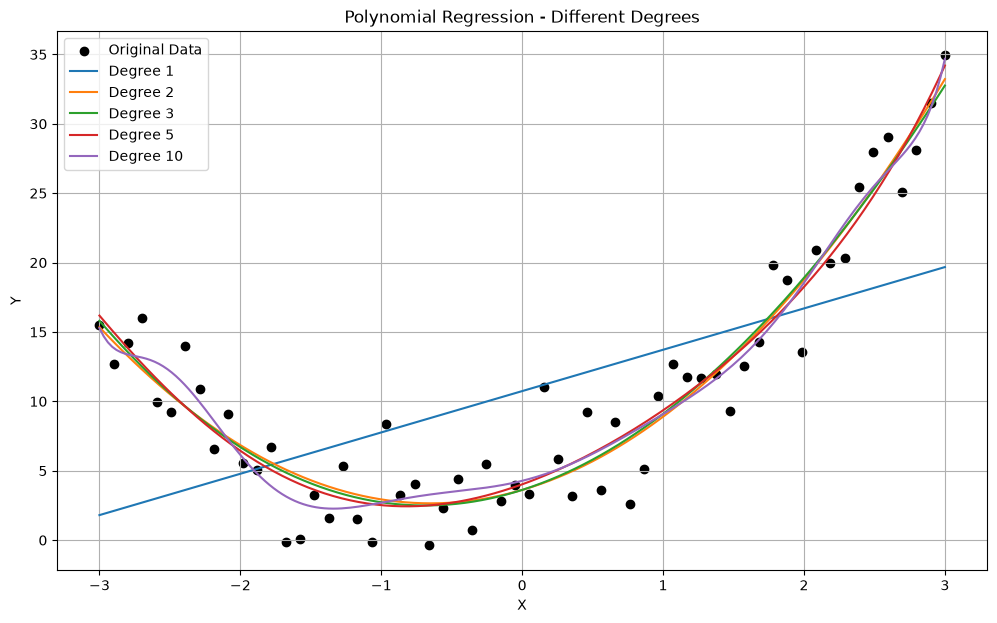

In [28]:
degrees = [1, 2, 3, 5, 10]

# Generate smooth X values for curve
X_plot = np.linspace(-3, 3, 200).reshape(-1, 1)

plt.figure(figsize=(12, 7))
plt.scatter(X, y, color='black', label='Original Data')

# train separate model
for degree in degrees:
    poly = PolynomialFeatures(
        degree=degree,
        include_bias=False
    )

    X_ploy = poly.fit_transform(X)

    model = LinearRegression()
    model.fit(X_ploy, y)

    X_plot_poly = poly.transform(X_plot)

    y_predict = model.predict(X_plot_poly)

    plt.plot(X_plot, y_predict, label=f'Degree {degree}')


plt.xlabel('X')
plt.ylabel('Y')
plt.title('Polynomial Regression - Different Degrees')
plt.legend()

plt.grid(True)
plt.show()

### D3

In [29]:
# import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split

# given that we have data set
np.random.seed(42)

X = np.linspace(-3, 3, 60)

y = (
    2 * X**2
    + 3 * X
    + 5
    + np.random.normal(0, 3, 60)
)

X = X.reshape(-1, 1)

degrees = [1, 2, 3, 5, 10]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

result = []

for degree in degrees:

    poly = PolynomialFeatures(degree=degree, include_bias=False)

    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    # Predictions on training data
    train_pred = model.predict(X_train_poly)

    # Predictions on testing data
    test_pred = model.predict(X_test_poly)

    # Calculate errors
    train_mse = mean_squared_error(y_train, train_pred)

    test_mse = mean_squared_error(y_test, test_pred)

    result.append({
        "Degree": degree,
        "Training MSE": train_mse,
        "Testing MSE": test_mse
    })

result_df = pd.DataFrame(result)
print(result_df.to_string(index=False))

 Degree  Training MSE  Testing MSE
      1     47.034529    48.892994
      2      7.141182     4.738392
      3      7.124910     4.649568
      5      6.752663     5.614858
     10      6.230373     6.672710
